# 03 · Cancellation model: which bookings will be cancelled?

**Question:** can we flag, on the day a booking is made, which bookings are likely to be cancelled?

**Rules:**
- Use only information **known at booking time** (no data leakage).
- Train on arrivals in **2015–2016**, test on arrivals in **2017**: learn from the past, predict the future.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix)

df = pd.read_csv("../data/processed/hotel_bookings_clean.csv", parse_dates=["arrival_date"])
print(df.shape)

(119208, 36)


## 4.1 One more leakage check: parking spaces
`required_car_parking_spaces` looks harmless, but when is it recorded? Check the cancellation rate of bookings with at least one parking space.

In [3]:
(df.groupby(df["required_car_parking_spaces"] > 0)["is_canceled"].mean() * 100).round(1)

required_car_parking_spaces
False    39.5
True      0.0
Name: is_canceled, dtype: float64

required_car_parking_spaces is also leakage: bookings with a parking space are never cancelled (0.0% vs 39.5%), most likely because the space is recorded at arrival. Excluded from the model.

## 4.2 Features
Columns grouped by type. Excluded on purpose:
- **Leakage (known only after booking):** `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `required_car_parking_spaces` (see 4.1)
- **Built from the outcome:** `is_duplicate` (computed on all columns, including `is_canceled`)
- **Not useful / redundant:** `arrival_date`, `arrival_date_year`, `revenue`, `agent` (an ID with hundreds of values)

In [4]:
# Keep the 20 most common countries, group the rest as "Other"
top_countries = df["country"].value_counts().index[:20]
df["country_grp"] = df["country"].where(df["country"].isin(top_countries), "Other")

NUM = ["lead_time", "arrival_date_week_number", "stays_in_weekend_nights", "stays_in_week_nights",
       "adults", "children", "babies", "is_repeated_guest", "previous_cancellations",
       "previous_bookings_not_canceled", "days_in_waiting_list", "adr",
       "total_of_special_requests", "has_company"]
CAT = ["hotel", "arrival_date_month", "meal", "country_grp", "market_segment",
       "distribution_channel", "reserved_room_type", "deposit_type", "customer_type"]
TARGET = "is_canceled"

## 4.3 Time-based split
Train = arrivals before 2017, test = arrivals in 2017 (January–August).

In [5]:
train = df[df["arrival_date"] < "2017-01-01"]
test = df[df["arrival_date"] >= "2017-01-01"]

X_train, y_train = train[NUM + CAT], train[TARGET]
X_test, y_test = test[NUM + CAT], test[TARGET]

print(f"Train: {len(train):,} bookings, cancellation rate {y_train.mean():.1%}")
print(f"Test:  {len(test):,} bookings, cancellation rate {y_test.mean():.1%}")

Train: 78,589 bookings, cancellation rate 36.2%
Test:  40,619 bookings, cancellation rate 38.7%


## 4.4 Baselines
A model is only useful if it beats simple rules:
- **Always "not cancelled"** (the most common outcome)
- **Simple rule:** flag bookings made more than 90 days ahead or with a Non Refund deposit

In [6]:
def evaluate(name, y_true, y_pred, y_score=None):
    """Return the main metrics of a prediction as one table row."""
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 3),
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 3),
        "recall": round(recall_score(y_true, y_pred), 3),
        "roc_auc": round(roc_auc_score(y_true, y_score), 3) if y_score is not None else None,
    }

results = []
results.append(evaluate("Always 'not cancelled'", y_test, np.zeros(len(y_test), dtype=int)))

rule = ((X_test["lead_time"] > 90) | (X_test["deposit_type"] == "Non Refund")).astype(int)
results.append(evaluate("Rule: lead time > 90 or Non Refund", y_test, rule))

pd.DataFrame(results)

,model,accuracy,precision,recall,roc_auc
0,Always 'not cancelled',0.613,0.000,0.000,None
1,Rule: lead time > 90 or Non Refund,0.631,0.518,0.669,None


## 4.5 Models
Two models in a **pipeline** (preparation + model in one object, fitted on the training data only):
- **Logistic regression:** simple and explainable
- **Random forest:** many decision trees voting together; captures non-linear patterns

In [7]:
prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

models = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                            n_jobs=-1, random_state=42),
}

fitted = {}
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train, y_train)
    score = pipe.predict_proba(X_test)[:, 1]
    results.append(evaluate(name, y_test, (score >= 0.5).astype(int), score))
    fitted[name] = pipe

pd.DataFrame(results)

,model,accuracy,precision,recall,roc_auc
0,Always 'not cancelled',0.613,0.000,0.000,NaN
1,Rule: lead time > 90 or Non Refund,0.631,0.518,0.669,NaN
2,Logistic regression,0.763,0.804,0.515,0.839
3,Random forest,0.768,0.795,0.542,0.846


## 4.6 Confusion matrix of the best model

In [8]:
best = fitted["Random forest"]
test_score = best.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, (test_score >= 0.5).astype(int))
pd.DataFrame(cm, index=["Actual: stayed", "Actual: cancelled"],
             columns=["Predicted: stay", "Predicted: cancel"])

,Predicted: stay,Predicted: cancel
Actual: stayed,22685,2200
Actual: cancelled,7206,8528


Both models clearly beat the baselines on precision (~80% vs 52%) and accuracy (77% vs 63%), with ROC AUC 0.85 (random forest) and 0.84 (logistic regression: a simple model is almost as good). At the default 0.5 threshold, recall (54%) is lower than the simple rule (67%): the model flags only bookings it is confident about. The threshold is a business choice, addressed in notebook 04.

## 4.7 How much does the model rely on Non Refund blocks?
Train the same random forest **without** `deposit_type` and compare.

In [9]:
CAT_NO_DEP = [c for c in CAT if c != "deposit_type"]
prep_no_dep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_NO_DEP),
])
pipe_no_dep = Pipeline([("prep", prep_no_dep),
                        ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                         n_jobs=-1, random_state=42))])
pipe_no_dep.fit(X_train[NUM + CAT_NO_DEP], y_train)
score_no_dep = pipe_no_dep.predict_proba(X_test[NUM + CAT_NO_DEP])[:, 1]
results.append(evaluate("Random forest (no deposit_type)", y_test,
                        (score_no_dep >= 0.5).astype(int), score_no_dep))
pd.DataFrame(results)

,model,accuracy,precision,recall,roc_auc
0,Always 'not cancelled',0.613,0.000,0.000,NaN
1,Rule: lead time > 90 or Non Refund,0.631,0.518,0.669,NaN
2,Logistic regression,0.763,0.804,0.515,0.839
3,Random forest,0.768,0.795,0.542,0.846
4,Random forest (no deposit_type),0.764,0.791,0.533,0.840


## 4.8 Which features matter most?
**Permutation importance:** shuffle one column at a time in the test set and measure how much ROC AUC drops. A big drop = the model relies on that column.

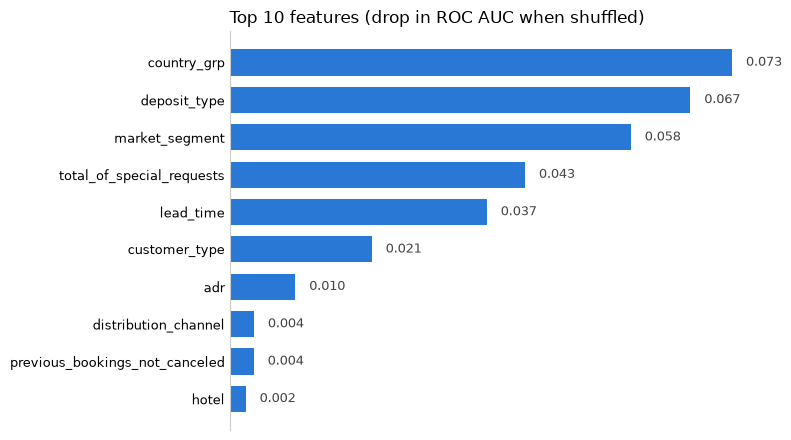

In [10]:
from sklearn.inspection import permutation_importance

sample = X_test.sample(min(5000, len(X_test)), random_state=42)
imp = permutation_importance(best, sample, y_test.loc[sample.index], scoring="roc_auc",
                             n_repeats=5, random_state=42, n_jobs=-1)
importance = (pd.Series(imp.importances_mean, index=sample.columns)
                .sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 4.5))
imp_sorted = importance.sort_values()
ax.barh(imp_sorted.index, imp_sorted.values, color="#2a78d6", height=0.7)
for i, v in enumerate(imp_sorted.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9, color="#444")
ax.xaxis.set_visible(False)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color("#ccc")
ax.tick_params(axis="y", labelsize=9, length=0)
ax.set_title("Top 10 features (drop in ROC AUC when shuffled)", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# 1. Cancellation rate of the 8 most common countries
top8 = df["country"].value_counts().index[:8]
c = df[df["country"].isin(top8)].groupby("country").agg(
    n_bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
)
c["cancel_rate"] = (c["cancel_rate"] * 100).round(1)
display(c.sort_values("n_bookings", ascending=False))

,n_bookings,cancel_rate
country,,
PRT,48482,56.7
GBR,12119,20.2
FRA,10401,18.6
ESP,8560,25.4
DEU,7285,16.7
ITA,3761,35.4
IRL,3374,24.7
BEL,2342,20.2


In [14]:
# 2. Same random forest without country
NUM_ = NUM
CAT_NO_COUNTRY = [c for c in CAT if c != "country_grp"]
prep_nc = ColumnTransformer([
    ("num", StandardScaler(), NUM_),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_NO_COUNTRY),
])
pipe_nc = Pipeline([("prep", prep_nc),
                    ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                     n_jobs=-1, random_state=42))])
pipe_nc.fit(X_train[NUM_ + CAT_NO_COUNTRY], y_train)
score_nc = pipe_nc.predict_proba(X_test[NUM_ + CAT_NO_COUNTRY])[:, 1]
results.append(evaluate("Random forest (no country)", y_test,
                        (score_nc >= 0.5).astype(int), score_nc))
pd.DataFrame(results)

,model,accuracy,precision,recall,roc_auc
0,Always 'not cancelled',0.613,0.000,0.000,NaN
1,Rule: lead time > 90 or Non Refund,0.631,0.518,0.669,NaN
2,Logistic regression,0.763,0.804,0.515,0.839
3,Random forest,0.768,0.795,0.542,0.846
4,Random forest (no deposit_type),0.764,0.791,0.533,0.840
5,Random forest (no country),0.761,0.784,0.529,0.824


In [15]:
# Final model = random forest without country
final = pipe_nc
FINAL_FEATURES = NUM_ + CAT_NO_COUNTRY
test_score = final.predict_proba(X_test[FINAL_FEATURES])[:, 1]

out = test[["hotel", "arrival_date", "lead_time", "deposit_type", "market_segment",
            "adr", "total_nights", "revenue", "is_canceled"]].copy()
out["cancel_score"] = test_score
out.to_csv("../data/processed/test_predictions.csv", index=False)
print(out.shape)

(40619, 10)


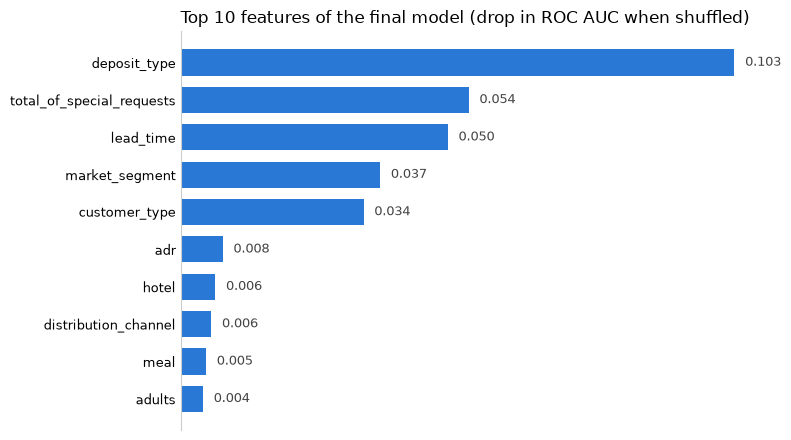

In [16]:
sample = X_test[FINAL_FEATURES].sample(5000, random_state=42)
imp = permutation_importance(final, sample, y_test.loc[sample.index], scoring="roc_auc",
                             n_repeats=5, random_state=42, n_jobs=-1)
importance = (pd.Series(imp.importances_mean, index=sample.columns)
                .sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 4.5))
imp_sorted = importance.sort_values()
ax.barh(imp_sorted.index, imp_sorted.values, color="#2a78d6", height=0.7)
for i, v in enumerate(imp_sorted.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9, color="#444")
ax.xaxis.set_visible(False)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color("#ccc")
ax.tick_params(axis="y", labelsize=9, length=0)
ax.set_title("Top 10 features of the final model (drop in ROC AUC when shuffled)", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

**1. Leakage removed before modelling.**
`reservation_status`, `reservation_status_date`, `assigned_room_type` and `booking_changes` are set after booking. `required_car_parking_spaces` is also leakage: bookings with a parking space are never cancelled (0.0% vs 39.5%), most likely because the space is recorded at arrival.

**2. The model clearly beats simple rules.**
Trained on 2015–2016 arrivals and tested on 2017, the random forest reaches ROC AUC 0.85 and flags cancellations with ~80% precision (vs 52% for a "lead time > 90 days or Non Refund" rule). Logistic regression is almost as good (0.84). At the default 0.5 threshold recall is lower than the rule (54% vs 67%): the threshold is a business choice (notebook 04).

**3. A slightly weaker model that can be trusted.**
`country` was the top feature: guests from Portugal cancel 56.7% of the time vs 17–35% for other countries. Since nationality may be recorded or corrected at check-in, the final model excludes it (ROC AUC 0.846 → 0.824). Removing `deposit_type` instead barely changes the result (0.840): other features capture the same group blocks.

**4. The model relies on the same signals found in the analysis.**
Top features of the final model: deposit type, special requests, lead time, market segment and customer type.

**Final model:** random forest without `country`: accuracy 76.1%, precision 78.4%, recall 52.9%, ROC AUC 0.824.